In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.optim.lr_scheduler import StepLR

import numpy as np
import matplotlib.pyplot as plt

import easydict

# Load datasets

In [2]:
import deeplake
dstrain = deeplake.load("hub://activeloop/cifar10-train")
dstest = deeplake.load("hub://activeloop/cifar10-test")

C:\Users\TRBU\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\deeplake\util\check_latest_version.py:32: UserWarning: A newer version of deeplake (3.9.18) is available. It's recommended that you update to the latest version using `pip install -U deeplake`.
  warnings.warn(
-

Opening dataset in read-only mode as you don't have write permissions.


-

This dataset can be visualized in Jupyter Notebook by ds.visualize() or at https://app.activeloop.ai/activeloop/cifar10-train



/

hub://activeloop/cifar10-train loaded successfully.



Opening dataset in read-only mode as you don't have write permissions.


\

This dataset can be visualized in Jupyter Notebook by ds.visualize() or at https://app.activeloop.ai/activeloop/cifar10-test



/

hub://activeloop/cifar10-test loaded successfully.



# Train NN

In [3]:
def train(args, model, device, train_loader, optimizer, epoch):
    model.train()
    for batch_idx, data in enumerate(train_loader):
        target = data.popitem()[1].squeeze()
        images = data.popitem()[1]
        images, target = images.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(images)
        loss = F.nll_loss(output, target)
        loss.backward()
        optimizer.step()
        if batch_idx % args.log_interval == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(images), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item()))
            if args.dry_run:
                break


def test(model, device, test_loader):
    model.eval()
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for data in test_loader:
            target = data.popitem()[1].squeeze()
            images = data.popitem()[1]
            images, target = images.to(device), target.to(device)
            output = model(images)
            test_loss += F.nll_loss(output, target, reduction='sum').item()  # sum up batch loss
            pred = output.argmax(dim=1, keepdim=True)  # get the index of the max log-probability
            correct += pred.eq(target.view_as(pred)).sum().item()

    test_loss /= len(test_loader.dataset)

    print('\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
        test_loss, correct, len(test_loader.dataset),
        100. * correct / len(test_loader.dataset)))

In [4]:
# Training settings
args = easydict.EasyDict({
    "batch_size": 100,
    "test_batch_size": 10000,
    "train_steps": 1000,
    "no_cuda": False,
    "no_mps": True,
    "seed": 1,
    "lr": 0.05, 
    "gamma": 0.7,
    "epochs": 10,
    "dry_run": False,
    "log_interval": 10,
    "save_model": False
})
use_cuda = not args.no_cuda and torch.cuda.is_available()
use_mps = not args.no_mps and torch.backends.mps.is_available()

torch.manual_seed(args.seed)

if use_cuda:
    device = torch.device("cuda")
elif use_mps:
    device = torch.device("mps")
else:
    device = torch.device("cpu")

train_kwargs = {'batch_size': args.batch_size}
test_kwargs = {'batch_size': args.test_batch_size}
if use_cuda:
    cuda_kwargs = {'num_workers': 1,
                    'pin_memory': True,
                    'shuffle': True}
    train_kwargs.update(cuda_kwargs)
    test_kwargs.update(cuda_kwargs)

tform = transforms.Compose([
    transforms.ToPILImage(), # Must convert to PIL image for subsequent operations to run
    transforms.RandomRotation(20), # Image augmentation
    transforms.ToTensor(), # Must convert to pytorch tensor for subsequent operations to run
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

#PyTorch Dataloader
train_loader= dstrain.pytorch(batch_size = args.batch_size, num_workers = 1, transform = {'images': tform, 'labels': None}, shuffle = False)
test_loader= dstest.pytorch(batch_size = args.test_batch_size, num_workers = 1, transform = {'images': tform, 'labels': None}, shuffle = False)

model = torch.hub.load('pytorch/vision:v0.10.0', 'resnet50', pretrained=True)
model.to(device)
optimizer = optim.Adadelta(model.parameters(), lr=args.lr)

scheduler = StepLR(optimizer, step_size=1, gamma=args.gamma)
for epoch in range(1, args.epochs + 1):
    train(args, model, device, train_loader, optimizer, epoch)
    test(model, device, test_loader)
    scheduler.step()

if args.save_model:
    torch.save(model.state_dict(), "cifar10.pt")


C:\Users\TRBU\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\deeplake\integrations\pytorch\common.py:137: UserWarning: Decode method for tensors ['images'] is defaulting to numpy. Please consider specifying a decode_method in .pytorch() that maximizes the data preprocessing speed based on your transformation.
  warnings.warn(
Using cache found in C:\Users\TRBU/.cache\torch\hub\pytorch_vision_v0.10.0
C:\Users\TRBU\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\TRBU\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other t

Train Epoch: 1 [0/50000 (0%)]	Loss: 0.620816
Train Epoch: 1 [1000/50000 (2%)]	Loss: -3.370033
Train Epoch: 1 [2000/50000 (4%)]	Loss: -8.588400
Train Epoch: 1 [3000/50000 (6%)]	Loss: -15.938594
Train Epoch: 1 [4000/50000 (8%)]	Loss: -22.653206
Train Epoch: 1 [5000/50000 (10%)]	Loss: -27.683876
Train Epoch: 1 [6000/50000 (12%)]	Loss: -37.926983
Train Epoch: 1 [7000/50000 (14%)]	Loss: -43.457207
Train Epoch: 1 [8000/50000 (16%)]	Loss: -51.036076
Train Epoch: 1 [9000/50000 (18%)]	Loss: -52.807484
Train Epoch: 1 [10000/50000 (20%)]	Loss: -65.960510
Train Epoch: 1 [11000/50000 (22%)]	Loss: -64.844963
Train Epoch: 1 [12000/50000 (24%)]	Loss: -82.903809
Train Epoch: 1 [13000/50000 (26%)]	Loss: -89.294617
Train Epoch: 1 [14000/50000 (28%)]	Loss: -94.471115
Train Epoch: 1 [15000/50000 (30%)]	Loss: -116.539696
Train Epoch: 1 [16000/50000 (32%)]	Loss: -128.211929
Train Epoch: 1 [17000/50000 (34%)]	Loss: -133.539459
Train Epoch: 1 [18000/50000 (36%)]	Loss: -146.064163
Train Epoch: 1 [19000/50000 (3

# Tests on trained NN

In [5]:
model.eval()
with torch.no_grad():
    for data, target in test_loader:
        data, target = data.to(device), target.to(device)
        output = model(data)
        pred = output.argmax(dim=1, keepdim=True)  # get the index of the max log-probability
        pred2 = torch.topk(output, k=2, dim=1)[1][:,1] # index of second largest log-prob
        pred2 = pred2.reshape(pred2.shape[0],1)


## Correct classified vs actual number as a function of ML confidence for max log-prob

In [6]:
## Transform to range [0,1]
output_softmax = torch.softmax(output, dim=1)  
## Select largest entry
selected_entries = torch.gather(output_softmax, 1, pred)

In [7]:
step = 0.05
cat = 1

binMean = []
correctFreq = []
error = []
correct = []
for value in np.arange(0, 1.0, step):
    start = value
    end = start+step

    # Select entries with convidence in interval (start,end]
    conf_in_range = selected_entries[(selected_entries>start) & (selected_entries<=end)]
    pred_in_range = pred[(selected_entries>start) & (selected_entries<=end)]
    targ_in_range = target[[(selected_entries>start)[:,0] & (selected_entries<=end)[:,0]]].squeeze()
    
    binMean.append( start + step/2 )
    correct.append( (pred_in_range == targ_in_range).sum().item() )
    correctFreq.append( (pred_in_range == targ_in_range).sum().item()/targ_in_range.shape[0] if targ_in_range.shape[0]!=0 else 0 )
    error.append( np.sqrt((pred_in_range == targ_in_range).sum().item())/targ_in_range.shape[0] if targ_in_range.shape[0]!=0 else 0 )

plt.plot([0,1], [0,1], '--', color='grey')
plt.errorbar(binMean, correctFreq, error, marker='.', linestyle='', color='blue')
plt.xlabel("NN output")
plt.ylabel("Fraction correct classified")
plt.show()

IndexError: tuple index out of range

## Classwise check 

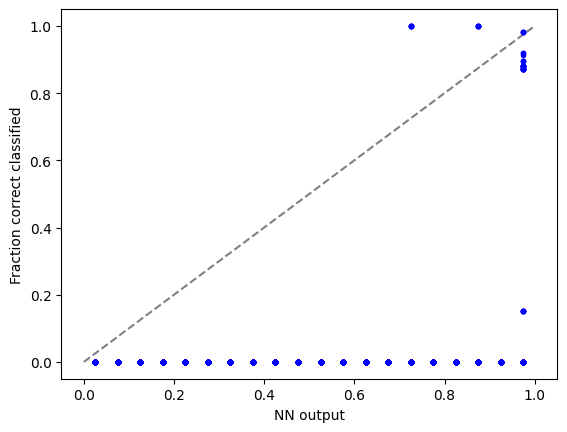

In [8]:
step = 0.05

binMean = []
correctFreq = []
error = []
correct = []

plt.plot([0,1], [0,1], '--', color='grey')
for cat in np.arange(0,10):
    for value in np.arange(0, 1.0, step):
        start = value
        end = start+step

        # Select entries with convidence in interval (start,end]
        conf_in_range = selected_entries[(selected_entries>start) & (selected_entries<=end)]
        pred_in_range = pred[(selected_entries>start) & (selected_entries<=end)]
        targ_in_range = target[[(selected_entries>start)[:,0] & (selected_entries<=end)[:,0]]].squeeze()

        # Confine to only entries with target = cat
        conf_in_range = conf_in_range[targ_in_range==cat]
        pred_in_range = pred_in_range[targ_in_range==cat]
        targ_in_range = targ_in_range[targ_in_range==cat]

        binMean.append( start + step/2 )
        correct.append( (pred_in_range == targ_in_range).sum().item() )
        correctFreq.append( (pred_in_range == targ_in_range).sum().item()/targ_in_range.shape[0] if targ_in_range.shape[0]!=0 else 0 )
        error.append( np.sqrt((pred_in_range == targ_in_range).sum().item())/targ_in_range.shape[0] if targ_in_range.shape[0]!=0 else 0 )
    plt.plot(binMean, correctFreq, marker='.', linestyle='', linewidth=0.1, color='blue')

plt.xlabel("NN output")
plt.ylabel("Fraction correct classified")
plt.show()

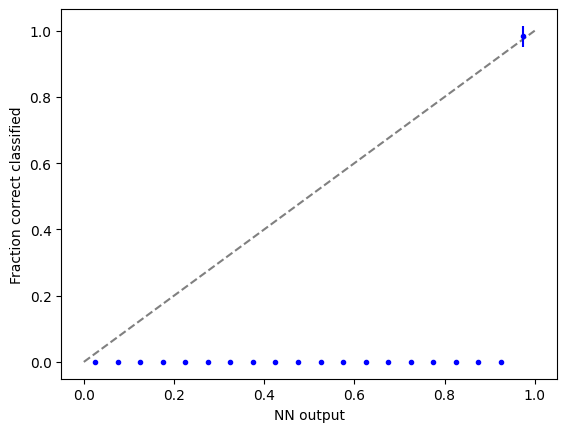

: 

In [9]:
step = 0.05

binMean = []
correctFreq = []
error = []
correct = []

plt.plot([0,1], [0,1], '--', color='grey')
cat = 6

for value in np.arange(0, 1.0, step):
    start = value
    end = start+step

    # Select entries with convidence in interval (start,end]
    conf_in_range = selected_entries[(selected_entries>start) & (selected_entries<=end)]
    pred_in_range = pred[(selected_entries>start) & (selected_entries<=end)]
    targ_in_range = target[[(selected_entries>start)[:,0] & (selected_entries<=end)[:,0]]].squeeze()

    # Confine to only entries with target = cat
    conf_in_range = conf_in_range[targ_in_range==cat]
    pred_in_range = pred_in_range[targ_in_range==cat]
    targ_in_range = targ_in_range[targ_in_range==cat]

    binMean.append( start + step/2 )
    correct.append( (pred_in_range == targ_in_range).sum().item() )
    correctFreq.append( (pred_in_range == targ_in_range).sum().item()/targ_in_range.shape[0] if targ_in_range.shape[0]!=0 else 0 )
    error.append( np.sqrt((pred_in_range == targ_in_range).sum().item())/targ_in_range.shape[0] if targ_in_range.shape[0]!=0 else 0 )

plt.errorbar(binMean, correctFreq, error, marker='.', linestyle='', color='blue')
plt.xlabel("NN output")
plt.ylabel("Fraction correct classified")
plt.show()